# Прототип гибридной системы рекомендаций книг

## 1. Цель проекта
Объединим Popularity, Content-Based, Item-Based CF и SVD, затем добавим
нейросетевой ранжировщик Wide & Deep. Порядок разделов соответствует `task.md`.
Код моделей находится прямо в ноутбуке; запуск — **Restart Kernel → Run All**.

Это учебный прототип: по умолчанию берём 6000 случайных пользователей,
оцениваем до 150 пользователей каждого сегмента и обучаем сеть 5 эпох на CPU.
`max_users=None` и `eval_per_segment=None` включают полную выборку.
Результаты ограниченной выборки нельзя автоматически переносить на весь датасет.

In [1]:
from pathlib import Path
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.sparse import csr_matrix
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MultiLabelBinarizer, normalize
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "task.md").exists())
CONFIG = dict(seed=42, max_users=6000, eval_per_segment=150, k=10,
              candidates_per_model=60, neighbors=40, factors=24,
              epochs=5, batch_size=2048, learning_rate=0.003)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.set_num_threads(2)

set_seed(CONFIG["seed"])

## 2. Основа проекта: домашнее задание №1
В `Teplayakov_AN_HOME1.ipynb` уже есть EDA и четыре базовые модели,
в `eda_2.ipynb` — расширенные признаки. Ниже повторяем нужные части в едином
самодостаточном процессе, чтобы все модели использовали одно разбиение.

SVD здесь — усечённое разложение разреженной матрицы через `TruncatedSVD`.
Это простой вариант матричной факторизации без пользовательских смещений;
он отличается от SGD-SVD библиотеки Surprise из ДЗ.

Рейтинги соответствуют `books.id`, а теги — `books.book_id`. Глобальные
`average_rating`, `ratings_count` и `ratings_1…5` каталога не используем:
они могли включать отложенные взаимодействия.

Каталог: 10,000; оценки: 981,756


,id,title,authors
0,1,"The Hunger Games (The Hunger Games, #1)",Suzanne Collins
1,2,Harry Potter and the Sorcerer's Stone (Harry P...,"J.K. Rowling, Mary GrandPré"
2,3,"Twilight (Twilight, #1)",Stephenie Meyer
3,4,To Kill a Mockingbird,Harper Lee
4,5,The Great Gatsby,F. Scott Fitzgerald


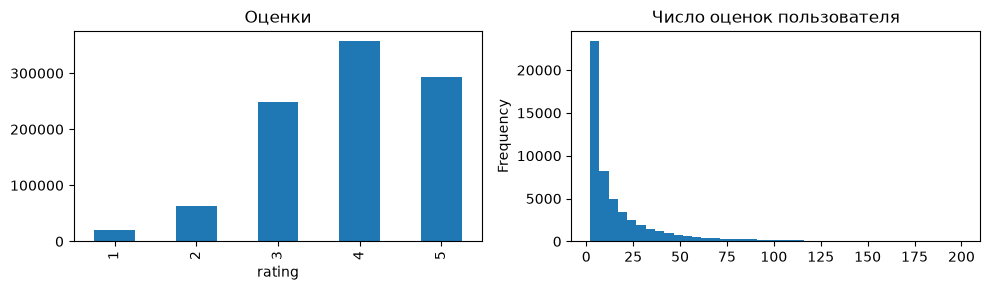

In [2]:
def load_data(data_dir):
    books = pd.read_csv(data_dir / "books.csv")
    ratings = pd.read_csv(data_dir / "ratings.csv")
    tags = pd.read_csv(data_dir / "tags.csv")
    book_tags = pd.read_csv(data_dir / "book_tags.csv")
    return books, ratings, tags, book_tags

raw_data = load_data(ROOT / "data/raw")
books_raw, ratings_raw, tags_raw, book_tags_raw = raw_data
print(f"Каталог: {len(books_raw):,}; оценки: {len(ratings_raw):,}")
display(books_raw[["id", "title", "authors"]].head())
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
ratings_raw.rating.value_counts().sort_index().plot.bar(ax=axes[0], title="Оценки")
ratings_raw.groupby("user_id").size().plot.hist(
    bins=40, ax=axes[1], title="Число оценок пользователя")
plt.tight_layout()
plt.show()

## 3. Задачи и этапы работы
### 3.1. Этап 1. Улучшенная подготовка данных

Сначала усредняем повторные пары пользователь–книга. Для пользователей с двумя
и более книгами откладываем примерно по 15% в validation и test, оставляя
хотя бы одну книгу в train. Одиночные оценки остаются в train.
Дополнительно по 2% пользователей полностью исключаем из train для validation
и test: это проверка настоящего холодного старта. Эти группы не пересекаются.
Без временных меток разбиение случайное, а не хронологическое.

Все статистики рейтингов и истории вычисляем **только по train**. Метаданные
и теги всего каталога считаем доступными заранее. `to_read` не используем:
это отдельный тип обратной связи, его трактовка требует отдельного эксперимента.

In [3]:
def split_ratings(ratings, book_ids, cfg):
    ratings = ratings.dropna(subset=["user_id", "book_id", "rating"])
    ratings = ratings[ratings.book_id.isin(book_ids) & ratings.rating.between(1, 5)]
    ratings = ratings.groupby(["user_id", "book_id"], as_index=False).rating.mean()
    rng = np.random.default_rng(cfg["seed"])
    users = np.sort(ratings.user_id.unique())
    if cfg["max_users"] is not None and len(users) > cfg["max_users"]:
        users = rng.choice(users, cfg["max_users"], replace=False)
    users = rng.permutation(users)
    cold_count = int(len(users) * 0.02)
    val_cold, test_cold = users[:cold_count], users[cold_count:2*cold_count]
    ratings = ratings[ratings.user_id.isin(users)].copy()
    warm = ratings[~ratings.user_id.isin(np.r_[val_cold, test_cold])]
    warm = warm.sample(frac=1, random_state=cfg["seed"])
    size = warm.groupby("user_id").book_id.transform("size")
    position = warm.groupby("user_id").cumcount()
    n_test = np.where(size >= 2, np.maximum(1, (size * .15).astype(int)), 0)
    n_val = np.where(size >= 3, np.maximum(1, (size * .15).astype(int)), 0)
    test_mask = position < n_test
    val_mask = (position >= n_test) & (position < n_test + n_val)
    train = warm[~test_mask & ~val_mask].copy()
    val = pd.concat([warm[val_mask], ratings[ratings.user_id.isin(val_cold)]])
    test = pd.concat([warm[test_mask], ratings[ratings.user_id.isin(test_cold)]])
    return train, val, test

train, validation, test = split_ratings(ratings_raw, books_raw.id, CONFIG)
print(f"Train: {len(train):,}; validation: {len(validation):,}; test: {len(test):,}")
assert not set(zip(train.user_id, train.book_id)) & set(zip(test.user_id, test.book_id))
assert not set(zip(train.user_id, train.book_id)) & set(zip(validation.user_id, validation.book_id))
assert not set(zip(validation.user_id, validation.book_id)) & set(zip(test.user_id, test.book_id))

Train: 76,368; validation: 17,107; test: 17,955


#### 3.1.1. Признаки пользователей, книг и взаимодействий

Пользователь: средняя оценка, число оценок и активность (новые: 0–5 книг,
активные: больше 5). Без дат активность означает объём истории.
Книга: число читателей, средняя оценка, стандартное отклонение и число
различных оценок. Тематические категории выбираем из понятного списка жанров.

Для Content-Based используем TF-IDF названий и 20 самых частых тегов каждой
книги. Схожесть с историей — косинус между книгой и средним вектором
понравившихся книг (оценка ≥ 4). При отсутствии положительной истории профиль
нулевой. Жанры нужны для разнообразия и нейросети; TF-IDF — для близости.

In [4]:
GENRES = {"fantasy", "science-fiction", "romance", "mystery", "thriller",
          "horror", "historical-fiction", "non-fiction", "biography",
          "young-adult", "children", "classics", "poetry", "history"}

def prepare_features(raw_data, train):
    books, _, tags, book_tags = raw_data
    catalog = books[["id", "book_id", "title", "authors"]].copy().sort_values("id")
    named = book_tags.merge(tags, on="tag_id")
    top_tags = named.sort_values("count", ascending=False).groupby(
        "goodreads_book_id").head(20)
    texts = top_tags.groupby("goodreads_book_id").tag_name.agg(" ".join)
    genres = named[named.tag_name.isin(GENRES)].groupby(
        "goodreads_book_id").tag_name.agg(lambda x: sorted(set(x)))
    catalog["tags"] = catalog.book_id.map(texts).fillna("")
    catalog["genres"] = catalog.book_id.map(genres).apply(
        lambda x: x if isinstance(x, list) else [])
    catalog = catalog.rename(columns={"book_id": "goodreads_book_id", "id": "book_id"})
    catalog = catalog.set_index("book_id")
    user_stats = train.groupby("user_id").rating.agg(count="size", mean="mean")
    user_stats["segment"] = np.where(user_stats["count"] <= 5, "новые", "активные")
    book_stats = train.groupby("book_id").rating.agg(
        popularity="size", mean="mean", std="std", unique_ratings="nunique")
    catalog = catalog.join(book_stats)
    catalog["mean"] = catalog["mean"].fillna(train.rating.mean())
    columns = ["popularity", "std", "unique_ratings"]
    catalog[columns] = catalog[columns].fillna(0)
    vectorizer = TfidfVectorizer(max_features=12000, min_df=2, dtype=np.float32)
    content = vectorizer.fit_transform(catalog.title.fillna("") + " " + catalog.tags)
    encoder = MultiLabelBinarizer(classes=sorted(GENRES))
    genre_features = encoder.fit_transform(catalog.genres).astype(np.float32)
    return catalog, user_stats, content, genre_features

catalog, user_stats, content, genre_features = prepare_features(raw_data, train)
display(user_stats.head())
display(catalog[["title", "popularity", "mean", "std", "unique_ratings", "genres"]].head())

,count,mean,segment
user_id,,,
1,1,4.000000,новые
27,20,4.200000,активные
29,4,4.000000,новые
48,1,5.000000,новые
55,7,3.285714,активные


,title,popularity,mean,std,unique_ratings,genres
book_id,,,,,,
1,"The Hunger Games (The Hunger Games, #1)",2.0,4.00,1.414214,2.0,"[fantasy, romance, science-fiction, thriller, ..."
2,Harry Potter and the Sorcerer's Stone (Harry P...,5.0,3.60,1.516575,3.0,"[children, classics, fantasy, mystery, young-a..."
3,"Twilight (Twilight, #1)",4.0,2.75,2.061553,3.0,"[fantasy, horror, science-fiction, young-adult]"
4,To Kill a Mockingbird,6.0,4.50,0.836660,3.0,"[classics, historical-fiction, history, myster..."
5,The Great Gatsby,2.0,4.00,1.414214,2.0,"[classics, historical-fiction, romance, young-..."


### 3.2. Этап 2. Построение гибридной системы
#### 3.2.1. Обучение базовых моделей

- **Popularity:** число train-читателей, без индивидуального профиля.
- **Content-Based:** косинусная близость TF-IDF к положительной train-истории.
- **Item-Based CF:** до 40 ближайших книг по косинусу столбцов матрицы оценок;
  прогноз — средняя оценка соседей с весами сходства. Без соседей используем
  сглаженную среднюю книги (5 условных оценок со средним train).
- **SVD:** разложение матрицы `rating / 5` на 24 скрытых фактора,
  прогноз — скалярное произведение факторов пользователя и книги.

Матрицы истории разреженные. Поиск соседей делим на блоки, чтобы не хранить
плотную матрицу сходств всего каталога. Для неизвестного пользователя
персональные модели возвращают Popularity.

In [5]:
def fit_classic(train, catalog, user_stats, content, genre_features, cfg):
    item_ids = catalog.index.to_numpy()
    user_ids = user_stats.index.to_numpy()
    user_map = {u: i for i, u in enumerate(user_ids)}
    item_map = {b: i for i, b in enumerate(item_ids)}
    rows = train.user_id.map(user_map).to_numpy()
    cols = train.book_id.map(item_map).to_numpy()
    matrix = csr_matrix((train.rating.to_numpy(np.float32), (rows, cols)),
                        shape=(len(user_ids), len(item_ids)))
    liked = matrix.copy()
    liked.data = (liked.data >= 4).astype(np.float32)
    liked.eliminate_zeros()
    # Средний профиль и сумма имеют одинаковое направление после нормировки.
    profiles = normalize(liked @ content)
    history = (matrix != 0).astype(np.float32)

    # Отрицательные и нулевые сходства не используем; книгу саму с собой исключаем.
    item_matrix = matrix.T.tocsr()
    n_neighbors = min(cfg["neighbors"] + 1, len(item_ids))
    nearest = NearestNeighbors(n_neighbors=n_neighbors, metric="cosine", n_jobs=1)
    nearest.fit(item_matrix)
    graph_rows, graph_cols, graph_values = [], [], []
    for start in range(0, len(item_ids), 256):
        distance, indices = nearest.kneighbors(item_matrix[start:start+256])
        for offset, (ds, js) in enumerate(zip(distance, indices)):
            i = start + offset
            for d, j in zip(ds, js):
                if i != j and d < 1:
                    graph_rows.append(i)
                    graph_cols.append(j)
                    graph_values.append(1 - d)
    graph = csr_matrix((np.array(graph_values, dtype=np.float32),
                        (graph_rows, graph_cols)), shape=(len(item_ids), len(item_ids)))
    factors = min(cfg["factors"], min(matrix.shape) - 1)
    svd = TruncatedSVD(n_components=factors, random_state=cfg["seed"])
    user_factors = svd.fit_transform(matrix / 5)
    prior = train.rating.mean()
    fallback = ((catalog["mean"] * catalog.popularity + 5 * prior)
                / (catalog.popularity + 5)).to_numpy(np.float32)
    # Сжатые/масштабированные числовые признаки для нейросети.
    user_numeric = np.column_stack([user_stats["mean"] / 5,
                                   np.log1p(user_stats["count"]) / 10]).astype(np.float32)
    book_numeric = np.column_stack([catalog["mean"] / 5,
                                   np.log1p(catalog.popularity) / 10,
                                   catalog["std"] / 5,
                                   catalog.unique_ratings / 5]).astype(np.float32)
    book_numeric = np.column_stack([book_numeric, genre_features]).astype(np.float32)
    return dict(catalog=catalog, user_stats=user_stats, item_ids=item_ids,
                user_map=user_map, item_map=item_map, matrix=matrix,
                history=history, profiles=profiles, content=content, graph=graph,
                user_factors=user_factors, item_factors=svd.components_.T,
                fallback=fallback, user_numeric=user_numeric, book_numeric=book_numeric,
                prior=prior, cfg=cfg, genre_sets=[set(g) for g in catalog.genres])

def scale_scores(values):
    # Разные модели имеют разные шкалы. Приводим их к [0, 1] для каждого пользователя.
    values = np.asarray(values, dtype=np.float32)
    spread = np.ptp(values)
    return (values - values.min()) / spread if spread > 1e-8 else np.zeros_like(values)

def classic_scores(state, user_id):
    popularity = scale_scores(np.log1p(state["catalog"].popularity.to_numpy()))
    u = state["user_map"].get(user_id)
    if u is None:
        return {name: popularity.copy() for name in ["Popularity", "Content", "ItemCF", "SVD"]}
    history = state["matrix"].getrow(u)
    content_score = (state["profiles"].getrow(u) @ state["content"].T).toarray().ravel()
    numerator = (state["graph"] @ history.T).toarray().ravel()
    denominator = (state["graph"] @ state["history"].getrow(u).T).toarray().ravel()
    cf = np.divide(numerator, denominator, out=state["fallback"].copy(), where=denominator > 0)
    svd = state["item_factors"] @ state["user_factors"][u]
    return dict(Popularity=popularity, Content=scale_scores(content_score),
                ItemCF=scale_scores(cf), SVD=scale_scores(svd))

state = fit_classic(train, catalog, user_stats, content, genre_features, CONFIG)
print("Четыре базовые модели обучены")

Четыре базовые модели обучены


#### 3.2.2. Стратегия объединения и генерация кандидатов

Из каждой модели берём до 60 непрочитанных книг и объединяем списки.
Нормализованные прогнозы усредняем с весами. Для новых пользователей усиливаем
Popularity, для активных — персональные модели; без истории используем только
Popularity. Кандидаты индивидуальных моделей остаются доступны для оценки
по всему каталогу, чтобы было видно влияние ограничения пула у гибрида.

Разнообразие добавляем жадным MMR: `λ × релевантность − (1−λ) × максимальное
жанровое сходство с уже выбранными книгами`. Меньше λ — больше разнообразия.
Жанровое сходство — Jaccard; отсутствие жанров не означает известного сходства.
Все train-книги исключаем независимо от поставленной оценки.

In [6]:
BASE_WEIGHTS = {
    "новые": dict(Popularity=.55, Content=.20, ItemCF=.10, SVD=.15),
    "активные": dict(Popularity=.15, Content=.25, ItemCF=.25, SVD=.35),
}

def user_segment(state, user_id):
    if user_id not in state["user_map"]:
        return "новые"
    return state["user_stats"].loc[user_id, "segment"]

def unseen_positions(state, user_id):
    mask = np.ones(len(state["item_ids"]), dtype=bool)
    u = state["user_map"].get(user_id)
    if u is not None:
        mask[state["matrix"].getrow(u).indices] = False
    return np.flatnonzero(mask)

def top_positions(scores, positions, n):
    # Стабильная сортировка разрешает ничьи по порядку book_id.
    return positions[np.argsort(-scores[positions], kind="stable")[:n]]

def recommend(state, user_id, scores, model="Hybrid", weights=None, diversity=0.9):
    k = state["cfg"]["k"]
    available = unseen_positions(state, user_id)
    if model != "Hybrid":
        chosen = top_positions(scores[model], available, k)
        return state["item_ids"][chosen].tolist()
    weights = weights or BASE_WEIGHTS
    selected_weights = weights[user_segment(state, user_id)]
    if user_id not in state["user_map"]:
        selected_weights = {"Popularity": 1.0}
    assert sum(selected_weights.values()) > 0
    combined = sum(w * scores[name] for name, w in selected_weights.items())
    combined = combined / sum(selected_weights.values())
    pools = [top_positions(values, available, state["cfg"]["candidates_per_model"])
             for values in scores.values()]
    pool = sorted(set(np.concatenate(pools).tolist()))
    # При λ=1 разнообразие не влияет на порядок — достаточно обычной сортировки.
    if diversity == 1.0:
        chosen = top_positions(combined, np.array(pool, dtype=int), k)
        return state["item_ids"][chosen].tolist()
    genre_sets = state["genre_sets"]
    chosen = []
    while pool and len(chosen) < k:
        def mmr(i):
            similarities = [len(genre_sets[i] & genre_sets[j]) /
                            max(1, len(genre_sets[i] | genre_sets[j])) for j in chosen]
            return diversity * combined[i] - (1 - diversity) * max(similarities, default=0)
        best = max(pool, key=mmr)
        chosen.append(best)
        pool.remove(best)
    return state["item_ids"][chosen].tolist()

example_user = int(user_stats["count"].idxmax())
example_scores = classic_scores(state, example_user)
example_ids = recommend(state, example_user, example_scores)
display(catalog.loc[example_ids, ["title", "authors", "genres"]])
print("Неизвестный пользователь:", recommend(state, -1, classic_scores(state, -1)))

Неизвестный пользователь: [5900, 1141, 8685, 6701, 7387, 1989, 1456, 6107, 3321, 8379]


,title,authors,genres
book_id,,,
1675,The Book of Ruth,Jane Hamilton,"[classics, historical-fiction]"
291,Cutting for Stone,Abraham Verghese,"[historical-fiction, history, non-fiction]"
1316,The Story of Edgar Sawtelle,David Wroblewski,"[historical-fiction, mystery]"
436,The God of Small Things,Arundhati Roy,"[classics, historical-fiction, romance]"
414,Little Bee,Chris Cleave,[historical-fiction]
860,"The Bean Trees (Greer Family, #1)",Barbara Kingsolver,"[classics, young-adult]"
4639,Back Roads,Tawni O'Dell,"[mystery, romance, thriller, young-adult]"
459,A Man Called Ove,"Fredrik Backman, Henning Koch",[]
779,A Fine Balance,Rohinton Mistry,"[classics, historical-fiction, history]"


### 3.3. Этап 3. Оценка и оптимизация
#### 3.3.1. Метрики и протокол

Релевантны отложенные оценки ≥ 4. Precision@K = попадания / K,
Recall@K = попадания / число релевантных книг, nDCG@K учитывает позиции
через `1/log2(позиция + 1)`. Усредняем по пользователям с хотя бы одной
релевантной книгой. Это условная оценка; число исключённых пользователей
показываем отдельно. Test не используется для настройки.

Validation- и test-истории не добавляем в train. У всех моделей одинаковые
пользователи и фильтрация прочитанного. Отдельно смотрим новых, активных и
совсем неизвестных пользователей. Общий результат — среднее по выбранной
оценочной выборке, в которой сегменты могут иметь другие доли, чем в данных.

In [7]:
def ranking_metrics(recommended, relevant, k):
    hits = np.array([b in relevant for b in recommended[:k]], dtype=float)
    precision = hits.sum() / k
    recall = hits.sum() / len(relevant) if relevant else 0.0
    dcg = (hits / np.log2(np.arange(len(hits)) + 2)).sum()
    ideal = (1 / np.log2(np.arange(min(k, len(relevant))) + 2)).sum()
    return precision, recall, dcg / ideal if ideal else 0.0

def evaluation_users(frame, state):
    relevant = frame[frame.rating >= 4].groupby("user_id").book_id.agg(set).to_dict()
    groups = {"новые": [], "активные": []}
    for user_id in sorted(relevant):
        groups[user_segment(state, user_id)].append(user_id)
    rng = np.random.default_rng(state["cfg"]["seed"])
    users = []
    limit = state["cfg"]["eval_per_segment"]
    for group in groups.values():
        if limit is not None and len(group) > limit:
            group = rng.choice(group, limit, replace=False).tolist()
        users.extend(group)
    if not users:
        raise ValueError("Нет пользователей с релевантными отложенными книгами")
    print(f"Пользователей: {frame.user_id.nunique()}; без релевантных: "
          f"{frame.user_id.nunique() - len(relevant)}; оцениваем: {len(users)}")
    return users, relevant

def build_score_cache(state, users, neural=False):
    cache = {}
    for user_id in users:
        scores = classic_scores(state, user_id)
        if neural:
            scores["WideDeep"] = neural_scores(state, user_id, scores)
        cache[user_id] = scores
    return cache

def evaluate(state, cache, relevant, weights, diversity):
    rows = []
    for user_id, scores in cache.items():
        for name in list(scores) + ["Hybrid"]:
            ids = recommend(state, user_id, scores, name, weights, diversity)
            p, r, ndcg = ranking_metrics(ids, relevant[user_id], state["cfg"]["k"])
            rows.append(dict(user_id=user_id, model=name, segment=user_segment(state, user_id),
                             cold=user_id not in state["user_map"], precision=p, recall=r,
                             ndcg=ndcg, recommendations=ids))
    return pd.DataFrame(rows)

METRICS = ["precision", "recall", "ndcg"]
val_users, val_relevant = evaluation_users(validation, state)
val_cache = build_score_cache(state, val_users)

Пользователей: 4973; без релевантных: 993; оцениваем: 300


#### 3.3.2. Подбор весов по validation
Проверим три понятных набора весов и два значения λ. Это небольшая сетка для
прототипа, а не поиск глобального оптимума. Выбираем по macro nDCG@K на validation;
метрики test увидим только после выбора. Нулевые веса разрешены, но сумма положительна.

In [8]:
WEIGHT_OPTIONS = [
    BASE_WEIGHTS,
    {"новые": dict(Popularity=.70, Content=.15, ItemCF=.05, SVD=.10),
     "активные": dict(Popularity=.10, Content=.20, ItemCF=.30, SVD=.40)},
    {"новые": dict(Popularity=.40, Content=.30, ItemCF=.15, SVD=.15),
     "активные": dict(Popularity=.10, Content=.40, ItemCF=.20, SVD=.30)},
]

def tune_hybrid(state, cache, relevant, options):
    rows = []
    for index, weights in enumerate(options):
        for diversity in [0.85, 1.0]:
            values = []
            for user_id, scores in cache.items():
                ids = recommend(state, user_id, scores, weights=weights, diversity=diversity)
                values.append(ranking_metrics(ids, relevant[user_id], state["cfg"]["k"])[2])
            rows.append(dict(option=index, diversity=diversity, ndcg=np.mean(values)))
    table = pd.DataFrame(rows).sort_values("ndcg", ascending=False, kind="stable")
    best = table.iloc[0]
    return options[int(best.option)], float(best.diversity), table

best_weights, best_diversity, search_results = tune_hybrid(
    state, val_cache, val_relevant, WEIGHT_OPTIONS)
display(search_results)
print("Веса:", best_weights, "λ:", best_diversity)

Веса: {'новые': {'Popularity': 0.4, 'Content': 0.3, 'ItemCF': 0.15, 'SVD': 0.15}, 'активные': {'Popularity': 0.1, 'Content': 0.4, 'ItemCF': 0.2, 'SVD': 0.3}} λ: 1.0


,option,diversity,ndcg
5,2,1.00,0.075115
4,2,0.85,0.064530
1,0,1.00,0.050995
0,0,0.85,0.039763
3,1,1.00,0.036690
2,1,0.85,0.026131


#### 3.3.3. Сравнение моделей и сегментов на test
Помимо метрик считаем покрытие каталога, разнообразие жанров и среднюю train-
популярность рекомендаций. Разнообразие — среднее `1 − Jaccard` только по парам,
у которых известен хотя бы один жанр у каждой книги. Долю таких пар выводим:
иначе пропуски жанров могли бы искусственно улучшить показатель.

Пользователей: 5873; без релевантных: 1316; оцениваем: 300
Число пользователей в срезах:


,precision,recall,ndcg
model,,,
Content,0.025000,0.134666,0.087103
Hybrid,0.026000,0.124073,0.083037
ItemCF,0.004333,0.025220,0.015178
SVD,0.005333,0.012712,0.010619
Popularity,0.000333,0.000476,0.000265


precision    recall      ndcg
segment  model                                    
активные Content      0.034667  0.115999  0.082292
         Hybrid       0.041333  0.141478  0.102148
         ItemCF       0.004667  0.010441  0.006788
         Popularity   0.000667  0.000952  0.000530
         SVD          0.010667  0.025424  0.021238
новые    Content      0.015333  0.153333  0.091913
         Hybrid       0.010667  0.106667  0.063926
         ItemCF       0.004000  0.040000  0.023568
         Popularity   0.000000  0.000000  0.000000
         SVD          0.000000  0.000000  0.000000

segment   cold 
активные  False    150
новые     False    141
          True       9
Name: user_id, dtype: int64

,precision,recall,ndcg
model,,,
Content,0.0,0.0,0.0
Hybrid,0.0,0.0,0.0
ItemCF,0.0,0.0,0.0
Popularity,0.0,0.0,0.0
SVD,0.0,0.0,0.0


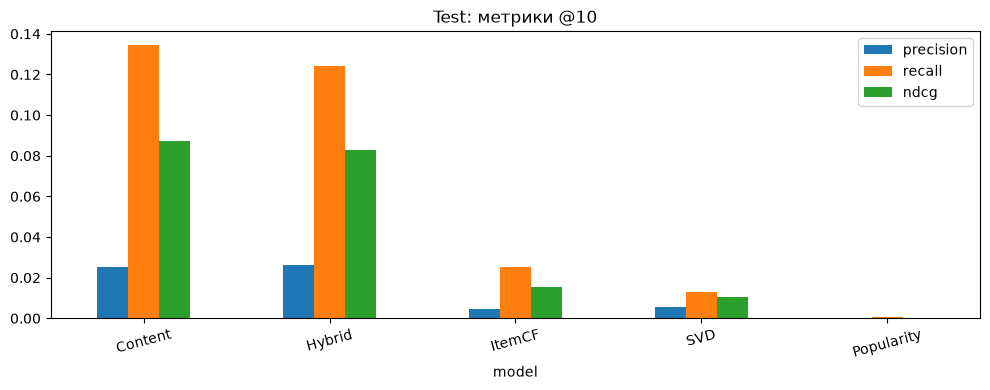

,coverage,genre_diversity,known_genre_pairs,mean_popularity
model,,,,
Content,0.1743,0.457349,0.994000,7.537000
Hybrid,0.1454,0.492965,0.986741,11.073667
ItemCF,0.1759,0.731844,0.989407,8.260333
Popularity,0.0011,0.790768,1.000000,17.996333
SVD,0.0526,0.463540,0.984000,11.725333


In [9]:
test_users, test_relevant = evaluation_users(test, state)
test_cache = build_score_cache(state, test_users)
base_details = evaluate(state, test_cache, test_relevant, best_weights, best_diversity)
base_comparison = base_details.groupby("model")[METRICS].mean().sort_values("ndcg", ascending=False)
display(base_comparison)
display(base_details.groupby(["segment", "model"])[METRICS].mean())
print("Число пользователей в срезах:")
display(base_details.groupby(["segment", "cold"]).user_id.nunique())
if base_details.cold.any():
    display(base_details[base_details.cold].groupby("model")[METRICS].mean())
base_comparison.plot.bar(figsize=(10, 4), rot=15, title=f"Test: метрики @{CONFIG['k']}")
plt.tight_layout()
plt.show()

def diversity_report(details, catalog):
    rows = []
    for name, frame in details.groupby("model"):
        lists = frame.recommendations.tolist()
        all_ids = [b for ids in lists for b in ids]
        distances, all_pairs = [], 0
        for ids in lists:
            genres = [set(catalog.loc[b, "genres"]) for b in ids]
            for i in range(len(genres)):
                for j in range(i):
                    all_pairs += 1
                    if genres[i] and genres[j]:
                        distances.append(1 - len(genres[i] & genres[j]) / len(genres[i] | genres[j]))
        rows.append(dict(model=name, coverage=len(set(all_ids)) / len(catalog),
                         genre_diversity=np.mean(distances) if distances else np.nan,
                         known_genre_pairs=len(distances) / max(1, all_pairs),
                         mean_popularity=catalog.loc[all_ids, "popularity"].mean()))
    return pd.DataFrame(rows).set_index("model")

display(diversity_report(base_details, catalog))

### 3.4. Продвинутая часть. Нейросетевой ранжировщик Wide & Deep
#### 3.4.1. Архитектура и обучение

**Wide** — линейный слой по простым признакам: средняя оценка и активность
пользователя, популярность/средняя/разброс/разнообразие оценок книги, её жанры,
косинусная схожесть с историей. **Deep** — эмбеддинги ID пользователя и книги
плюс те же признаки, два полносвязных слоя с ReLU. Сумму выходов пропускаем
через sigmoid, получаем оценку в [0, 1]. Обучаем MSE к `rating/5` на всех
train-оценках, включая низкие. Отрицательные непрочитанные примеры не создаём:
неизвестная оценка не равна отрицательному отзыву.

Это регрессия рейтинга для последующего ранжирования, а не оптимизация nDCG.
Статистики и признаки train-взаимодействия рассчитаны по общему train, поэтому
включают собственную оценку. Отложенные оценки туда не входят; для следующего
этапа развития полезны out-of-fold признаки обучающих взаимодействий.

Для неизвестных пользователей и книг без train-истории используем Popularity
и контент соответственно: случайные необученные ID-эмбеддинги не ранжируют каталог.
Число эпох фиксируем заранее; веса нейросетевого гибрида выбираем по validation.

Эпоха 1: train MSE = 0.05861
Эпоха 2: train MSE = 0.03910
Эпоха 3: train MSE = 0.03646
Эпоха 4: train MSE = 0.03274
Эпоха 5: train MSE = 0.02769


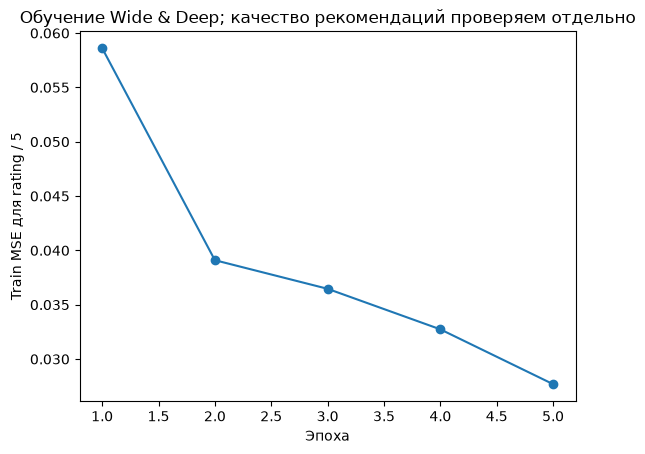

In [10]:
class WideDeep(nn.Module):
    def __init__(self, n_users, n_books, n_features):
        super().__init__()
        # Небольшие эмбеддинги запоминают индивидуальные вкусы и свойства книг.
        self.users = nn.Embedding(n_users, 16)
        self.books = nn.Embedding(n_books, 16)
        # Wide учит прямое влияние признаков; Deep — их нелинейные сочетания.
        self.wide = nn.Linear(n_features, 1)
        self.deep = nn.Sequential(nn.Linear(n_features + 32, 32), nn.ReLU(),
                                  nn.Linear(32, 16), nn.ReLU(), nn.Linear(16, 1))

    def forward(self, users, books, features):
        hidden = torch.cat([self.users(users), self.books(books), features], dim=1)
        return torch.sigmoid(self.wide(features) + self.deep(hidden)).squeeze(1)

def pair_features(state, users, books, similarity):
    return np.column_stack([state["user_numeric"][users], state["book_numeric"][books],
                            similarity]).astype(np.float32)

def fit_neural(state, train):
    set_seed(state["cfg"]["seed"])
    users = train.user_id.map(state["user_map"]).to_numpy(dtype=np.int64, copy=True)
    books = train.book_id.map(state["item_map"]).to_numpy(dtype=np.int64, copy=True)
    # Попарный косинус без плотной матрицы пользователь × весь каталог.
    similarity = np.asarray(state["profiles"][users].multiply(
        state["content"][books]).sum(axis=1)).ravel()
    features = pair_features(state, users, books, similarity)
    dataset = TensorDataset(torch.from_numpy(users), torch.from_numpy(books),
                            torch.from_numpy(features),
                            torch.tensor(train.rating.to_numpy(np.float32) / 5))
    loader = DataLoader(dataset, batch_size=state["cfg"]["batch_size"], shuffle=True)
    network = WideDeep(len(state["user_map"]), len(state["item_ids"]), features.shape[1])
    optimizer = torch.optim.Adam(network.parameters(), lr=state["cfg"]["learning_rate"],
                                 weight_decay=1e-5)
    losses = []
    for epoch in range(state["cfg"]["epochs"]):
        network.train()
        total = 0
        for user_batch, book_batch, x, y in loader:
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(network(user_batch, book_batch, x), y)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(y)
        losses.append(total / len(dataset))
        print(f"Эпоха {epoch + 1}: train MSE = {losses[-1]:.5f}")
    state["network"] = network.eval()
    return losses

@torch.no_grad()
def neural_scores(state, user_id, scores):
    u = state["user_map"].get(user_id)
    if u is None:
        return scores["Popularity"].copy()
    books = np.arange(len(state["item_ids"]), dtype=np.int64)
    users = np.full(len(books), u, dtype=np.int64)
    similarity = (state["profiles"].getrow(u) @ state["content"].T).toarray().ravel()
    features = pair_features(state, users, books, similarity)
    prediction = state["network"](torch.from_numpy(users), torch.from_numpy(books),
                                   torch.from_numpy(features)).numpy()
    prediction = scale_scores(prediction)
    cold_books = state["catalog"].popularity.to_numpy() == 0
    prediction[cold_books] = scores["Content"][cold_books]
    return prediction

losses = fit_neural(state, train)
plt.plot(range(1, len(losses) + 1), losses, marker="o")
plt.xlabel("Эпоха")
plt.ylabel("Train MSE для rating / 5")
plt.title("Обучение Wide & Deep; качество рекомендаций проверяем отдельно")
plt.show()

#### 3.4.2. Интеграция и сравнение с классическими методами
Добавляем Wide & Deep в общий пул кандидатов и во взвешенный прогноз.
На validation проверяем веса сети 0, 0.2 и 0.4; оставшиеся веса пропорционально
распределяем между классическими моделями. Нулевой вариант позволяет отказаться
от нейросети, если она не улучшает validation. При нулевом весе сеть всё ещё
влияет на пул кандидатов — это явно отличается от базового гибрида.

Выбранные веса: {'новые': {'Popularity': 0.24, 'Content': 0.18, 'ItemCF': 0.09, 'SVD': 0.09, 'WideDeep': 0.4}, 'активные': {'Popularity': 0.06, 'Content': 0.24, 'ItemCF': 0.12, 'SVD': 0.18, 'WideDeep': 0.4}} λ: 1.0


,option,diversity,ndcg
5,2,1.00,0.087116
3,1,1.00,0.086201
2,1,0.85,0.080144
4,2,0.85,0.078774
1,0,1.00,0.075115
0,0,0.85,0.064530


,precision,recall,ndcg
model,,,
Hybrid + NN,0.026333,0.133174,0.089722
Content,0.025000,0.134666,0.087103
Hybrid,0.026000,0.124073,0.083037
WideDeep,0.018333,0.112954,0.073150
ItemCF,0.004333,0.025220,0.015178
SVD,0.005333,0.012712,0.010619
Popularity,0.000333,0.000476,0.000265


precision    recall      ndcg
segment  model                                     
активные Content       0.034667  0.115999  0.082292
         Hybrid        0.041333  0.141478  0.102148
         Hybrid + NN   0.040000  0.139681  0.103816
         ItemCF        0.004667  0.010441  0.006788
         Popularity    0.000667  0.000952  0.000530
         SVD           0.010667  0.025424  0.021238
         WideDeep      0.023333  0.092575  0.058320
новые    Content       0.015333  0.153333  0.091913
         Hybrid        0.010667  0.106667  0.063926
         Hybrid + NN   0.012667  0.126667  0.075629
         ItemCF        0.004000  0.040000  0.023568
         Popularity    0.000000  0.000000  0.000000
         SVD           0.000000  0.000000  0.000000
         WideDeep      0.013333  0.133333  0.087980

,coverage,genre_diversity,known_genre_pairs,mean_popularity
model,,,,
Content,0.1743,0.457349,0.994000,7.537000
Hybrid,0.1454,0.492965,0.986741,11.073667
Hybrid + NN,0.1504,0.496247,0.985185,8.874000
ItemCF,0.1759,0.731844,0.989407,8.260333
Popularity,0.0011,0.790768,1.000000,17.996333
SVD,0.0526,0.463540,0.984000,11.725333
WideDeep,0.0931,0.573335,0.996074,5.306667


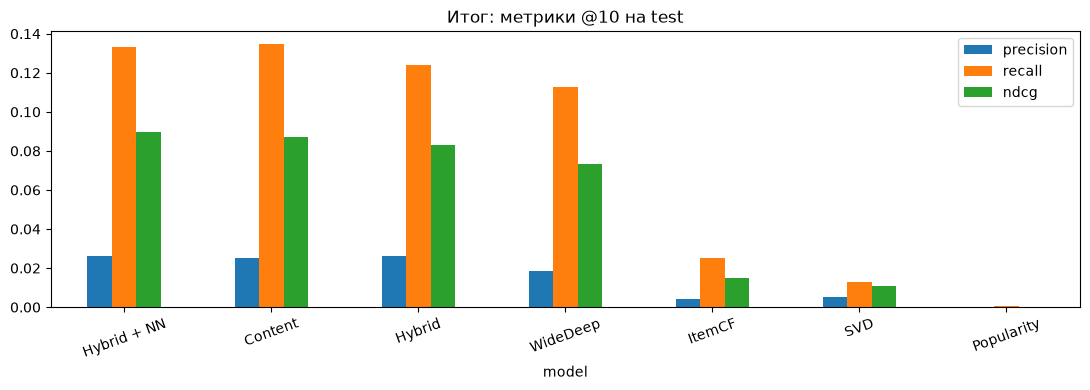

In [11]:
def neural_weight_options(classic_weights):
    options = []
    for neural_weight in [0.0, 0.2, 0.4]:
        weights = {}
        for segment, original in classic_weights.items():
            weights[segment] = {name: value * (1 - neural_weight)
                                for name, value in original.items()}
            weights[segment]["WideDeep"] = neural_weight
        options.append(weights)
    return options

# Базовые прогнозы уже рассчитаны; добавляем только прогноз сети.
for user_id, scores in val_cache.items():
    scores["WideDeep"] = neural_scores(state, user_id, scores)
neural_weights, neural_diversity, neural_search = tune_hybrid(
    state, val_cache, val_relevant, neural_weight_options(best_weights))
display(neural_search)
print("Выбранные веса:", neural_weights, "λ:", neural_diversity)
for user_id, scores in test_cache.items():
    scores["WideDeep"] = neural_scores(state, user_id, scores)
neural_details = evaluate(state, test_cache, test_relevant, neural_weights, neural_diversity)
# Сохраняем исходный гибрид, добавляем сеть отдельно и гибрид с её кандидатами.
new_rows = neural_details[neural_details.model.isin(["WideDeep", "Hybrid"])].copy()
new_rows.loc[new_rows.model == "Hybrid", "model"] = "Hybrid + NN"
final_details = pd.concat([base_details, new_rows], ignore_index=True)
comparison = final_details.groupby("model")[METRICS].mean().sort_values("ndcg", ascending=False)
display(comparison)
display(final_details.groupby(["segment", "model"])[METRICS].mean())
display(diversity_report(final_details, catalog))
comparison.plot.bar(figsize=(11, 4), rot=20, title=f"Итог: метрики @{CONFIG['k']} на test")
plt.tight_layout()
plt.show()

#### 3.4.3. Сквозной пайплайн и повторный запуск
Все вычисления выше оформлены простыми функциями. `run_pipeline` повторяет
загрузку → подготовку → обучение → подбор весов → рекомендации → оценку.
Передайте другую папку с теми же четырьмя CSV и другую конфигурацию.
Возвращаем обученные модели, выбранные веса и результаты. Validation не
добавляем в train после подбора: это сохраняет единый протокол сравнения.

Следующая ячейка определяет функцию, не повторяя длительное обучение автоматически.

In [12]:
def run_pipeline(data_dir, cfg=None, use_neural=True):
    cfg = {**CONFIG, **(cfg or {})}
    set_seed(cfg["seed"])
    raw = load_data(Path(data_dir))
    train, val, test = split_ratings(raw[1], raw[0].id, cfg)
    catalog, users, content, genres = prepare_features(raw, train)
    state = fit_classic(train, catalog, users, content, genres, cfg)
    val_users, val_relevant = evaluation_users(val, state)
    val_cache = build_score_cache(state, val_users)
    weights, diversity, _ = tune_hybrid(state, val_cache, val_relevant, WEIGHT_OPTIONS)
    test_users, test_relevant = evaluation_users(test, state)
    test_cache = build_score_cache(state, test_users)
    details = evaluate(state, test_cache, test_relevant, weights, diversity)
    if use_neural:
        fit_neural(state, train)
        for user_id, scores in val_cache.items():
            scores["WideDeep"] = neural_scores(state, user_id, scores)
        weights, diversity, _ = tune_hybrid(
            state, val_cache, val_relevant, neural_weight_options(weights))
        for user_id, scores in test_cache.items():
            scores["WideDeep"] = neural_scores(state, user_id, scores)
        extra = evaluate(state, test_cache, test_relevant, weights, diversity)
        extra = extra[extra.model.isin(["WideDeep", "Hybrid"])].copy()
        extra.loc[extra.model == "Hybrid", "model"] = "Hybrid + NN"
        details = pd.concat([details, extra], ignore_index=True)
    return dict(state=state, weights=weights, diversity=diversity, details=details,
                comparison=details.groupby("model")[METRICS].mean(),
                train=train, validation=val, test=test)

def recommend_books(state, user_id, weights, diversity):
    scores = classic_scores(state, user_id)
    if "network" in state:
        scores["WideDeep"] = neural_scores(state, user_id, scores)
    ids = recommend(state, user_id, scores, weights=weights, diversity=diversity)
    return state["catalog"].loc[ids, ["title", "authors", "genres"]]

# Новый запуск, в том числе на других данных:
# result = run_pipeline(ROOT / "data/raw", {"max_users": 3000, "epochs": 3})
# display(result["comparison"])
# display(recommend_books(result["state"], 123, result["weights"], result["diversity"]))
display(recommend_books(state, example_user, neural_weights, neural_diversity))

,title,authors,genres
book_id,,,
494,The Secret History,Donna Tartt,"[classics, historical-fiction, mystery, thriller]"
31,The Help,Kathryn Stockett,"[classics, historical-fiction, history, young-..."
100,The Poisonwood Bible,Barbara Kingsolver,"[classics, historical-fiction, history]"
1675,The Book of Ruth,Jane Hamilton,"[classics, historical-fiction]"
733,Snow Falling on Cedars,David Guterson,"[classics, historical-fiction, history, myster..."
291,Cutting for Stone,Abraham Verghese,"[historical-fiction, history, non-fiction]"
3313,The Gargoyle,Andrew Davidson,"[fantasy, historical-fiction, history, horror,..."
779,A Fine Balance,Rohinton Mistry,"[classics, historical-fiction, history]"
860,"The Bean Trees (Greer Family, #1)",Barbara Kingsolver,"[classics, young-adult]"


## 4. Проверка критериев качества
Проверим границы метрик, отсутствие повторов и прочитанного в выдаче.
Эти проверки контролируют корректность, но не доказывают превосходство гибрида.
Сравнение качества и различий между сегментами находится в таблицах выше.

In [13]:
assert np.allclose(ranking_metrics([1, 2], {1, 2}, 2), [1, 1, 1])
assert np.allclose(ranking_metrics([3, 4], {1, 2}, 2), [0, 0, 0])
assert np.allclose(ranking_metrics([1, 3], {1, 2}, 2)[:2], [.5, .5])
for row in final_details.itertuples():
    ids = row.recommendations
    assert len(ids) == len(set(ids)) == CONFIG["k"]
    u = state["user_map"].get(row.user_id)
    seen = set() if u is None else set(state["item_ids"][state["matrix"].getrow(u).indices])
    assert not seen.intersection(ids)
assert final_details[METRICS].ge(0).all().all()
assert final_details[METRICS].le(1 + 1e-8).all().all()
print("Проверки метрик, уникальности и фильтрации прочитанного пройдены")

Проверки метрик, уникальности и фильтрации прочитанного пройдены


## 5. Результаты и выводы
Числовые выводы формируем по текущему запуску. Рост качества не гарантирован:
гибрид или нейросеть могут уступать более простой модели. Общая оценка относится
к выбранным пользователям с положительным test-взаимодействием.

In [14]:
winner = comparison.ndcg.idxmax()
base_ndcg = comparison.loc["Hybrid", "ndcg"]
neural_ndcg = comparison.loc["Hybrid + NN", "ndcg"]
display(Markdown(
    f"Лучшая модель по test nDCG@{CONFIG['k']}: **{winner}** "
    f"({comparison.loc[winner, 'ndcg']:.4f}). "
    f"Гибрид: {base_ndcg:.4f}; гибрид с сетью: {neural_ndcg:.4f}; "
    f"абсолютная разница: {neural_ndcg - base_ndcg:+.4f}. "
    "Это наблюдение одного разбиения, без проверки статистической значимости."
))
segment_table = final_details.groupby(["segment", "model"]).ndcg.mean().unstack()
for segment, values in segment_table.iterrows():
    print(f"Сегмент «{segment}»: максимум nDCG у {values.idxmax()} ({values.max():.4f})")

Сегмент «активные»: максимум nDCG у Hybrid + NN (0.1038)
Сегмент «новые»: максимум nDCG у Content (0.0919)


Лучшая модель по test nDCG@10: **Hybrid + NN** (0.0897). Гибрид: 0.0830; гибрид с сетью: 0.0897; абсолютная разница: +0.0067. Это наблюдение одного разбиения, без проверки статистической значимости.

Сильные стороны и ограничения подходов:

- Popularity проста и работает без истории, но повторяет общий список и
  не различает вкусы. Нужна как опорная модель и fallback холодного старта.
- Content переносит знания на книги без оценок, но зависит от метаданных;
  теги вроде «to-read» описывают поведение, а не тему. Жанровый список неполон.
- ItemCF объясняется похожими книгами, но при короткой истории и разреженности
  часто опирается на fallback.
- SVD находит общие интересы, но трактует пропуски матрицы как нули и не
  оптимизирует непосредственно top-K; качество зависит от количества факторов.
- Wide & Deep объединяет числовые признаки, жанры и ID, но может переобучаться;
  снижение train MSE само по себе не доказывает улучшение рекомендаций.
- Гибрид зависит от шкал прогнозов и размера пула; MMR может снижать точность
  ради разнообразия. Сравнивать нужно одновременно ranking и диагностические метрики.

Практический выбор: ориентироваться на validation и стоимость выдачи; для нового
пользователя начать с популярного и собрать предпочтения, для активного использовать
персонализацию. Преимущество сети подтверждать повторными разбиениями и доверительными
интервалами. Следующие эксперименты: out-of-fold признаки для сети, настройка числа
факторов и соседей, несколько seed, временное разбиение при появлении дат,
контроль языков и очистка тегов. Неизвестные отзывы не считаются отрицательными,
поэтому offline-метрики неполны и не заменяют пользовательский эксперимент.

## 6. Формат сдачи
Самодостаточный Jupyter Notebook с кодом, пояснениями моделей, графиками,
сравнительными таблицами и повторно запускаемым пайплайном. Инструкция запуска —
в `README.md` в корне проекта.